# 1. 描述性统计

In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv('data/bank-full.csv', sep=';')
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [2]:
df.columns

Index(['age', 'job', 'marital', 'education', 'default', 'balance', 'housing',
       'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays',
       'previous', 'poutcome', 'y'],
      dtype='str')

marital：婚姻情况

default：有无违约记录

balance：余额

housing：有无住房贷款

loan：有无个人贷款

contact：联系方式

month：最后联系月份

day：最后联系的日期

duration：最后一次通话时长

compaign：宣传活动中的联系次数

pdays：上次营销活动联系之后的天数

previous：上次营销活动之前的联系次数

poutcome：上一次营销活动的结果

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        45211 non-null  int64
 1   job        45211 non-null  str  
 2   marital    45211 non-null  str  
 3   education  45211 non-null  str  
 4   default    45211 non-null  str  
 5   balance    45211 non-null  int64
 6   housing    45211 non-null  str  
 7   loan       45211 non-null  str  
 8   contact    45211 non-null  str  
 9   day        45211 non-null  int64
 10  month      45211 non-null  str  
 11  duration   45211 non-null  int64
 12  campaign   45211 non-null  int64
 13  pdays      45211 non-null  int64
 14  previous   45211 non-null  int64
 15  poutcome   45211 non-null  str  
 16  y          45211 non-null  str  
dtypes: int64(7), str(10)
memory usage: 5.9 MB


In [4]:
df.isnull().sum().sum(), df.duplicated().sum()

(np.int64(0), np.int64(0))

没有缺失值和重复值

In [5]:
df.describe()

,age,balance,day,duration,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000


pdays中-1表示该客户此前未被联系过，可以考虑将此前联系过的客户和未联系过的客户构造一个新特征。根据数据集中的描述，duration在预测时应舍弃。

从数据分布来看，balance有正有负且中位数和均值相差较大，存在偏态分布，后续可考虑保持正负号的对数变换；
previous与campaign也存在偏态

In [6]:
df.describe(include='str')

,job,marital,education,default,housing,loan,contact,month,poutcome,y
count,45211,45211,45211,45211,45211,45211,45211,45211,45211,45211
unique,12,3,4,2,2,2,3,12,4,2
top,blue-collar,married,secondary,no,yes,no,cellular,may,unknown,no
freq,9732,27214,23202,44396,25130,37967,29285,13766,36959,39922


In [7]:
df['education'].value_counts(), df['marital'].value_counts(), df['poutcome'].value_counts()

(education
 secondary    23202
 tertiary     13301
 primary       6851
 unknown       1857
 Name: count, dtype: int64,
 marital
 married     27214
 single      12790
 divorced     5207
 Name: count, dtype: int64,
 poutcome
 unknown    36959
 failure     4901
 other       1840
 success     1511
 Name: count, dtype: int64)

可以看出大部分变量为分类变量，可以进行独热编码，对二分类的可以转化为0，1

In [8]:
df['y'].value_counts()

y
no     39922
yes     5289
Name: count, dtype: int64

# 2. EDA

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams['font.sans-serif'] = ['Microsoft YaHei'] 
plt.rcParams['axes.unicode_minus'] = False

In [10]:
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [11]:
df['y'] = df['y'].replace({'yes': 1, 'no': 0}).astype(int)
df_number = df.select_dtypes(include='number').columns
df_str = df.select_dtypes(include='str').columns

df[df_number].corr(method='pearson')

,age,balance,day,duration,campaign,pdays,previous,y
age,1.000000,0.097783,-0.009120,-0.004648,0.004760,-0.023758,0.001288,0.025155
balance,0.097783,1.000000,0.004503,0.021560,-0.014578,0.003435,0.016674,0.052838
day,-0.009120,0.004503,1.000000,-0.030206,0.162490,-0.093044,-0.051710,-0.028348
duration,-0.004648,0.021560,-0.030206,1.000000,-0.084570,-0.001565,0.001203,0.394521
campaign,0.004760,-0.014578,0.162490,-0.084570,1.000000,-0.088628,-0.032855,-0.073172
pdays,-0.023758,0.003435,-0.093044,-0.001565,-0.088628,1.000000,0.454820,0.103621
previous,0.001288,0.016674,-0.051710,0.001203,-0.032855,0.454820,1.000000,0.093236
y,0.025155,0.052838,-0.028348,0.394521,-0.073172,0.103621,0.093236,1.000000


## 2.1 个人基本情况与目标变量的相关性
age, job, marital, education

In [12]:
df_1 = df[['age', 'job', 'marital', 'education', 'y']]
df_1['subscribed'] = (df_1['y'] == 1).astype(int)

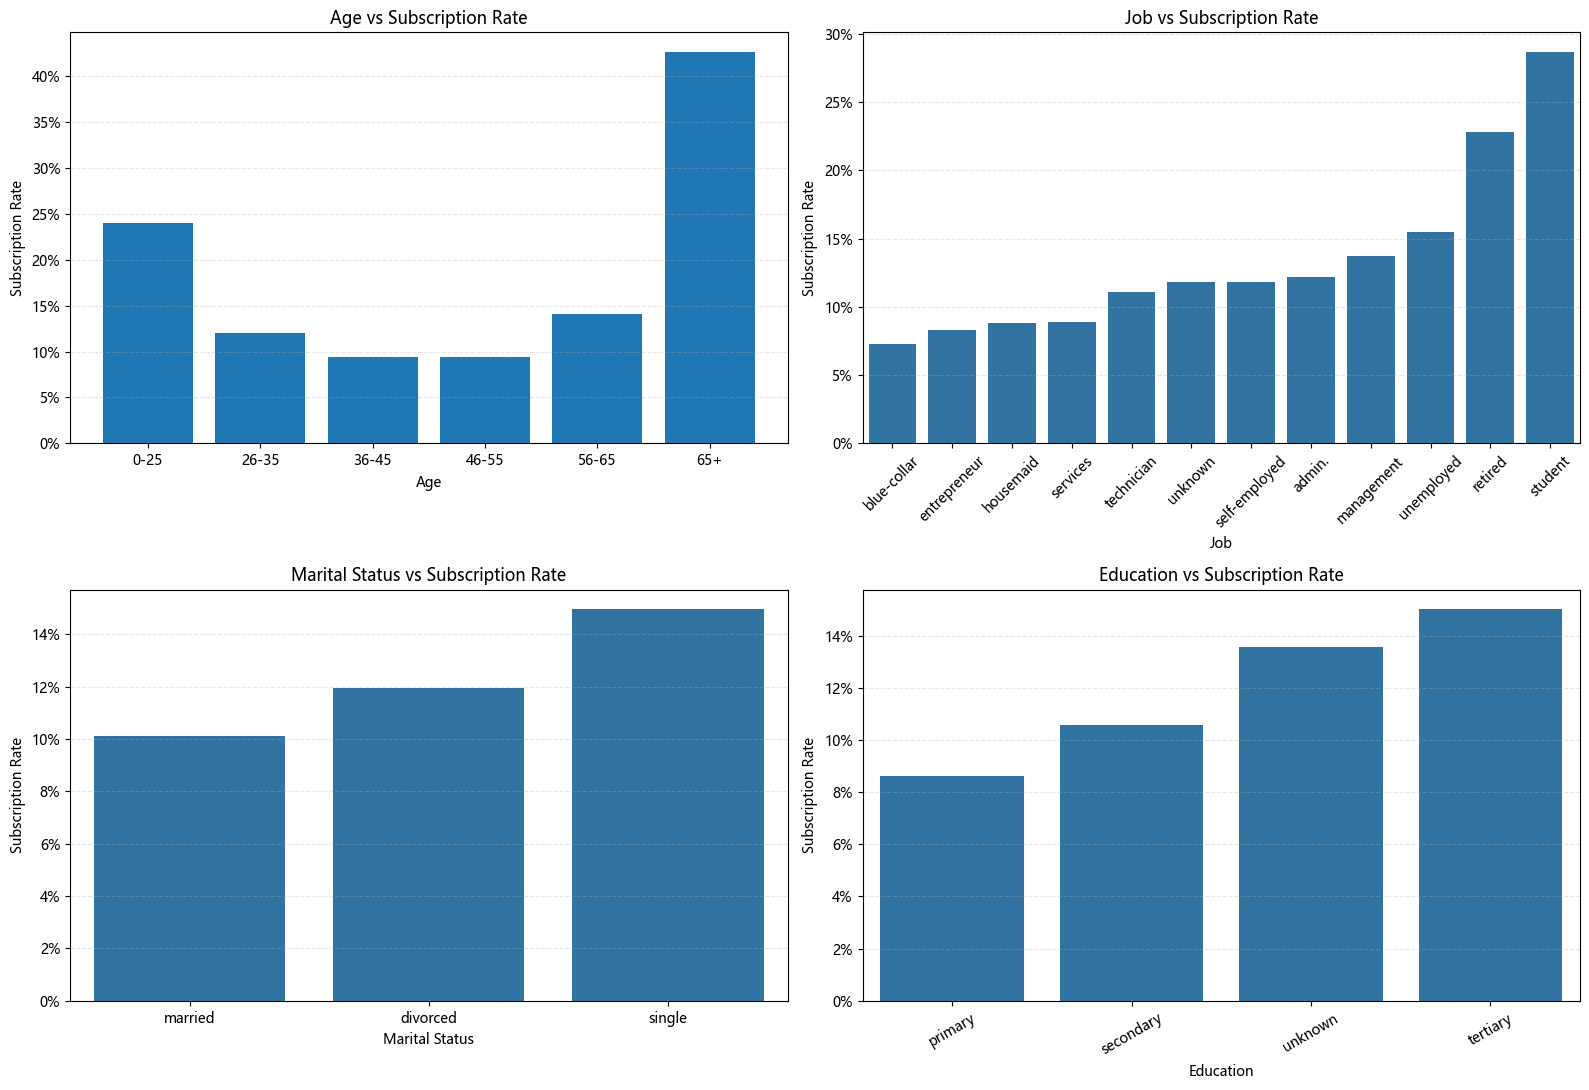

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# 1. 年龄与订阅率，年龄分组
df_1['age_group'] = pd.cut(df_1['age'], bins=[0, 25, 35, 45, 55, 65, 100], labels=['0-25', '26-35', '36-45', '46-55', '56-65', '65+'])
age_rate = df_1.groupby('age_group')['subscribed'].mean()
axes[0, 0].bar(age_rate.index, age_rate.values)
axes[0, 0].set_title('Age vs Subscription Rate')
axes[0, 0].set_xlabel('Age')
axes[0, 0].set_ylabel('Subscription Rate')

# 2. 职业与订阅率
job_rate = df_1.groupby('job')['subscribed'].mean().sort_values()
sns.barplot(x=job_rate.index, y=job_rate.values, ax=axes[0, 1])
axes[0, 1].set_title('Job vs Subscription Rate')
axes[0, 1].set_xlabel('Job')
axes[0, 1].set_ylabel('Subscription Rate')
axes[0, 1].tick_params(axis='x', rotation=45)

# 3. 婚姻状况与订阅率
marital_rate = df_1.groupby('marital')['subscribed'].mean().sort_values()
sns.barplot(x=marital_rate.index, y=marital_rate.values, ax=axes[1, 0])
axes[1, 0].set_title('Marital Status vs Subscription Rate')
axes[1, 0].set_xlabel('Marital Status')
axes[1, 0].set_ylabel('Subscription Rate')

# 4. 教育程度与订阅率
education_rate = df_1.groupby('education')['subscribed'].mean().sort_values()
sns.barplot(x=education_rate.index, y=education_rate.values, ax=axes[1, 1])
axes[1, 1].set_title('Education vs Subscription Rate')
axes[1, 1].set_xlabel('Education')
axes[1, 1].set_ylabel('Subscription Rate')
axes[1, 1].tick_params(axis='x', rotation=30)


for ax in axes.flat:
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.0%}'))
    ax.grid(axis='y', linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

结合年龄分组和job可以看出，学生（25岁以下）以及退休（65岁+）的订阅率相比更高，其他的差异不大；而在婚姻状况中，单身包含离异的订阅率更高；在受教育情况中，受过高等教育的订阅率更高

## 2.2 个人经济情况与目标变量的相关性
default, housing, loan, balance

In [14]:
df_2 = df[['default', 'balance', 'housing', 'loan']]
df_2['subscribed'] = (df['y'] == 1).astype(int)

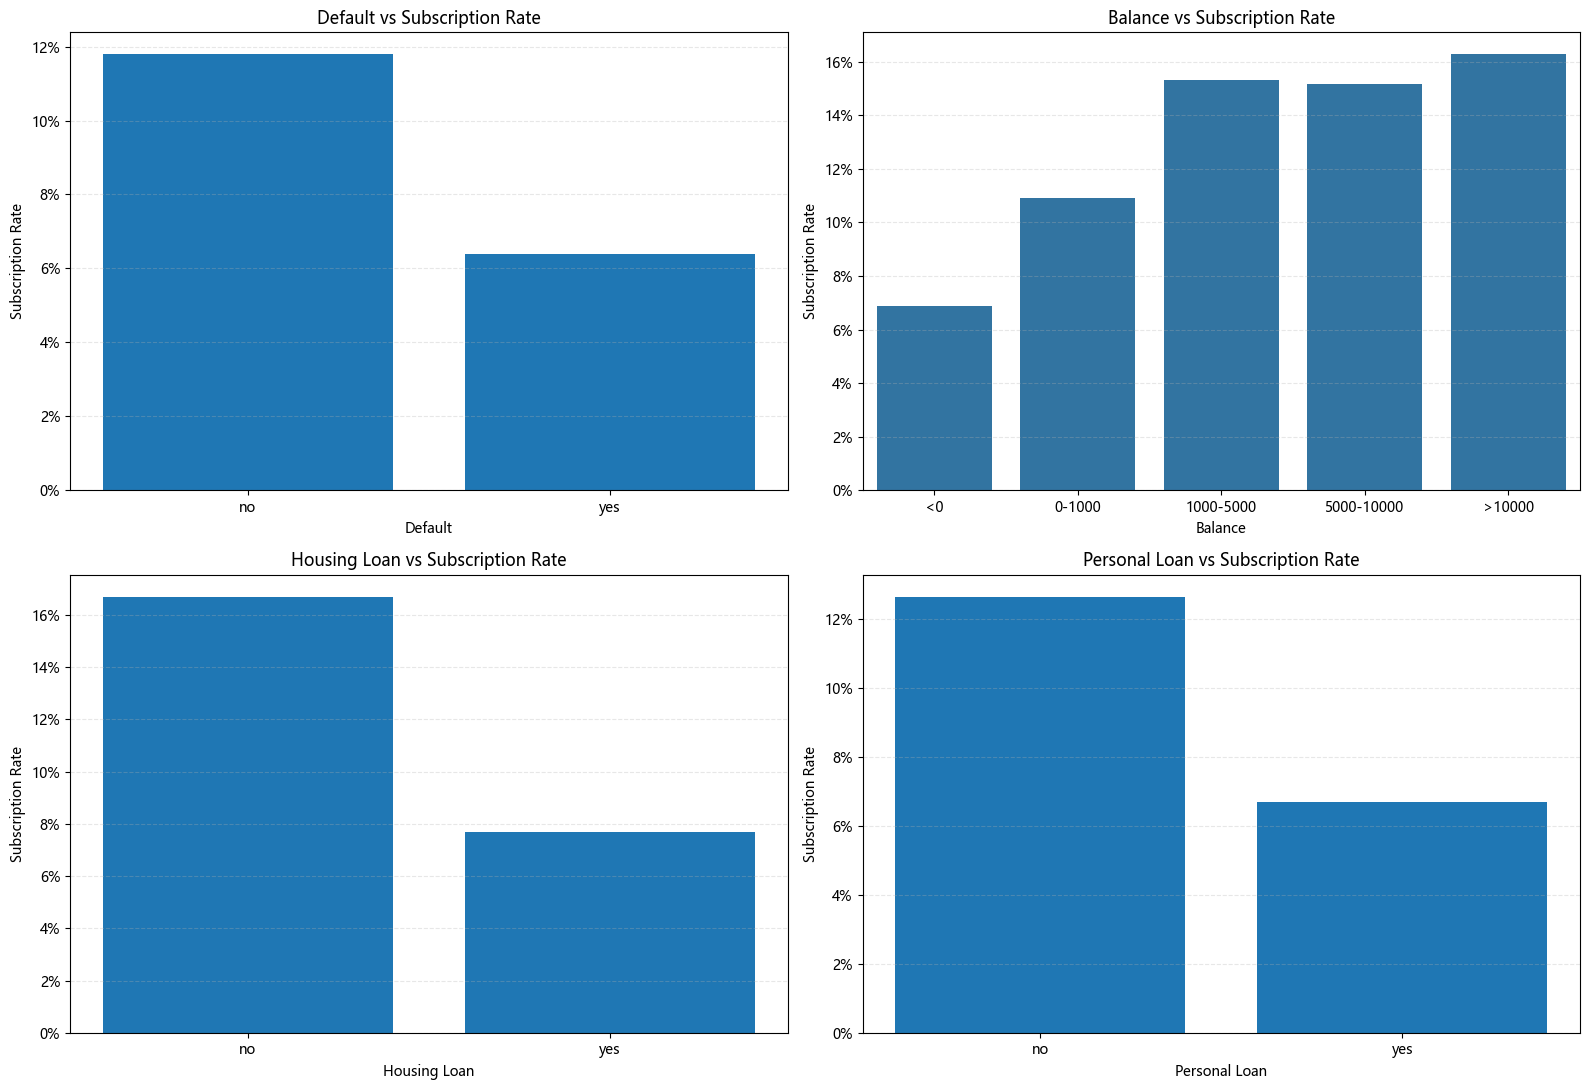

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# 1. 有无违约记录与订阅率
default_rate = df_2.groupby('default')['subscribed'].mean()
axes[0, 0].bar(default_rate.index, default_rate.values)
axes[0, 0].set_title('Default vs Subscription Rate')
axes[0, 0].set_xlabel('Default')
axes[0, 0].set_ylabel('Subscription Rate')

# 2. 账户余额与订阅率
# 余额分组
df_2['balance_group'] = pd.cut(df_2['balance'], bins=[-np.inf, 0, 1000, 5000, 10000, np.inf], labels=['<0', '0-1000', '1000-5000', '5000-10000', '>10000'])
balance_rate = df_2.groupby('balance_group')['subscribed'].mean()
sns.barplot(x=balance_rate.index, y=balance_rate.values, ax=axes[0, 1])
axes[0, 1].set_title('Balance vs Subscription Rate')
axes[0, 1].set_xlabel('Balance')
axes[0, 1].set_ylabel('Subscription Rate')

# 3. 有无住房贷款与订阅率
housing_rate = df_2.groupby('housing')['subscribed'].mean()
axes[1, 0].bar(housing_rate.index, housing_rate.values)
axes[1, 0].set_title('Housing Loan vs Subscription Rate')
axes[1, 0].set_xlabel('Housing Loan')
axes[1, 0].set_ylabel('Subscription Rate')

# 4. 有无个人贷款与订阅率
loan_rate = df_2.groupby('loan')['subscribed'].mean()
axes[1, 1].bar(loan_rate.index, loan_rate.values)
axes[1, 1].set_title('Personal Loan vs Subscription Rate')
axes[1, 1].set_xlabel('Personal Loan')
axes[1, 1].set_ylabel('Subscription Rate')

for ax in axes.flat:
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.0%}'))
    ax.grid(axis='y', linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

从上面四个图可以看出，经济情况更好的客户订阅率更高

## 2.3 营销性活动与目标变量的相关性
campaign, pdays, previous, contact, poutcome，duration（忽略）

month, day

In [16]:
df_3 = df[['campaign', 'pdays', 'previous', 'poutcome', 'contact', 'month', 'day']]
df_3['subscribed'] = (df['y'] == 1).astype(int)
df_3.head()

,campaign,pdays,previous,poutcome,contact,month,day,subscribed
0,1,-1,0,unknown,unknown,may,5,0
1,1,-1,0,unknown,unknown,may,5,0
2,1,-1,0,unknown,unknown,may,5,0
3,1,-1,0,unknown,unknown,may,5,0
4,1,-1,0,unknown,unknown,may,5,0


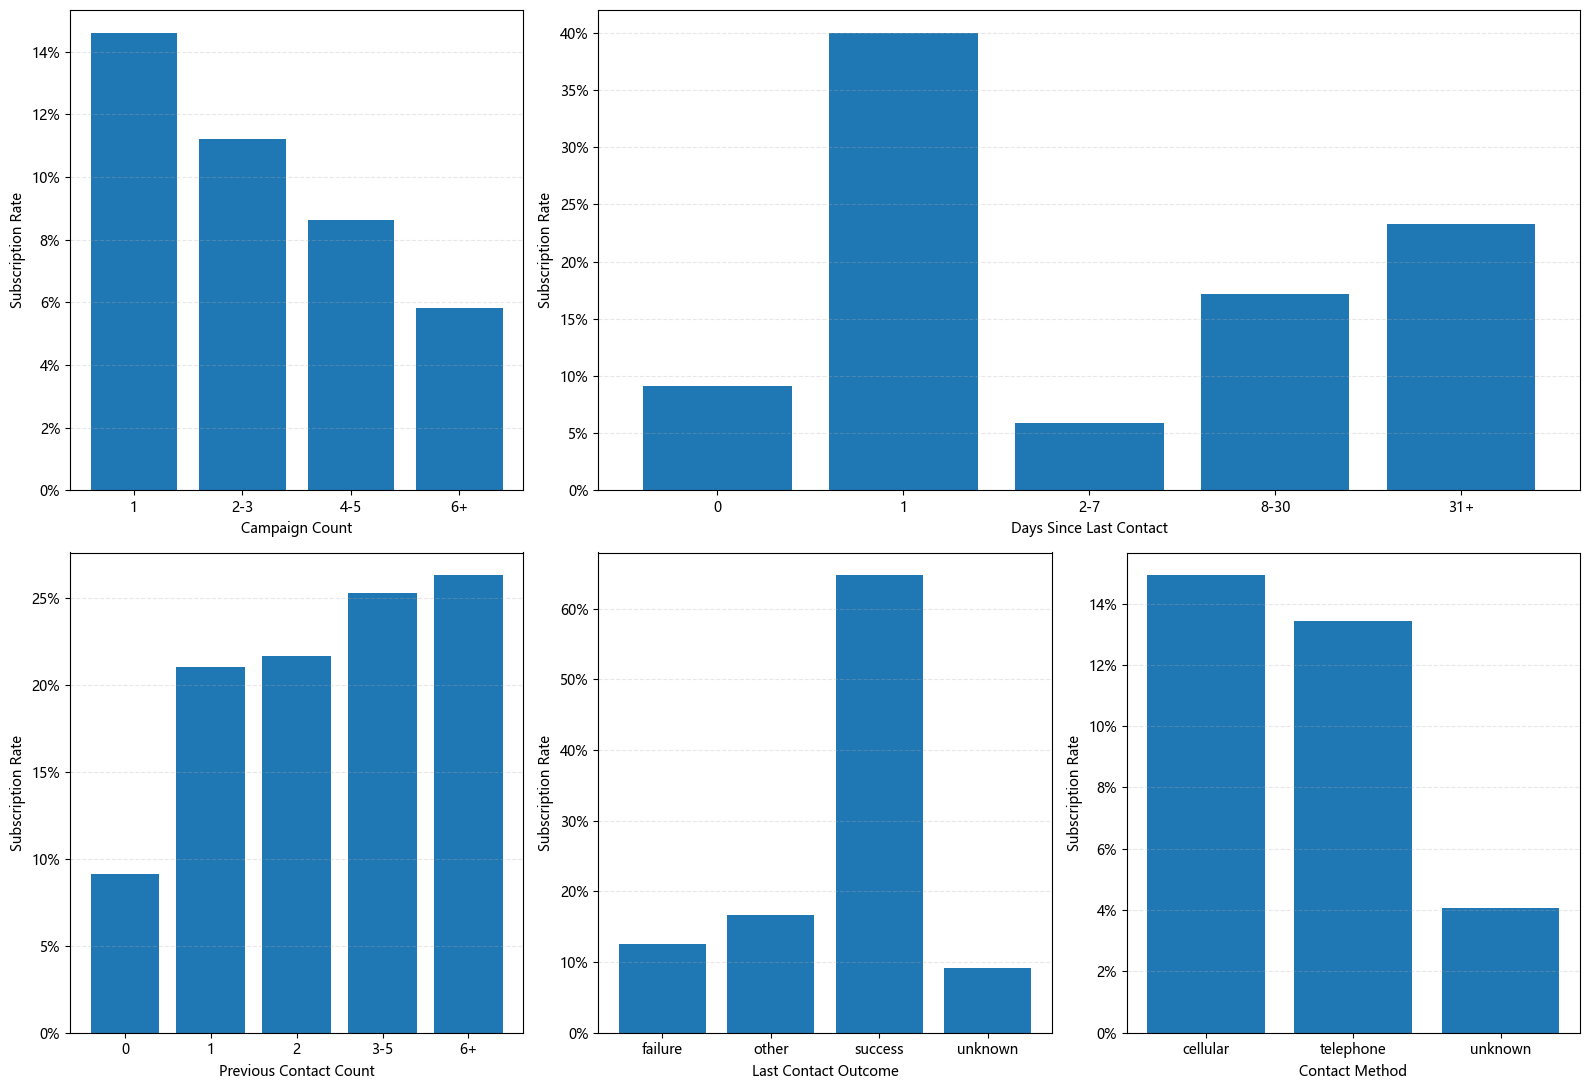

In [17]:
import matplotlib.gridspec as gridspec

fig = plt.figure(figsize=(16, 11))
gs = gridspec.GridSpec(2, 3, figure=fig)

ax1 = fig.add_subplot(gs[0, 0])       
ax2 = fig.add_subplot(gs[0, 1:3])     
ax3 = fig.add_subplot(gs[1, 0])       
ax4 = fig.add_subplot(gs[1, 1])       
ax5 = fig.add_subplot(gs[1, 2])      
axes = [ax1, ax2, ax3, ax4, ax5]      

# 1. 在本次营销活动中联系次数与订阅率
df_3['campaign_group'] = pd.cut(df_3['campaign'], bins=[0, 1, 3, 5, np.inf], labels=['1', '2-3', '4-5', '6+'])
campaign_rate = df_3.groupby('campaign_group')['subscribed'].mean()
ax1.bar(campaign_rate.index, campaign_rate.values)
ax1.set_xlabel('Campaign Count')
ax1.set_ylabel('Subscription Rate')

# 2. 上一次联系后天数与订阅率，天数分组
df_3['pdays_group'] = pd.cut(df_3['pdays'], bins=[-2, 0, 1, 7, 30, np.inf], labels=['0', '1', '2-7', '8-30', '31+'])
pdays_rate = df_3.groupby('pdays_group')['subscribed'].mean()
ax2.bar(pdays_rate.index, pdays_rate.values)
ax2.set_xlabel('Days Since Last Contact')
ax2.set_ylabel('Subscription Rate')

# 3. 联系方式与订阅率
contact_rate = df_3.groupby('contact')['subscribed'].mean()
ax5.bar(contact_rate.index, contact_rate.values)
ax5.set_xlabel('Contact Method')
ax5.set_ylabel('Subscription Rate')

# 4. 之前联系次数与订阅率，次数分组
df_3['previous_group'] = pd.cut(df_3['previous'], bins=[-2, 0, 1, 2, 5, np.inf], labels=['0', '1', '2', '3-5', '6+'])
previous_rate = df_3.groupby('previous_group')['subscribed'].mean()
ax3.bar(previous_rate.index, previous_rate.values)
ax3.set_xlabel('Previous Contact Count')
ax3.set_ylabel('Subscription Rate')

# 5. 上一次联系结果与订阅率
poutcome_rate = df_3.groupby('poutcome')['subscribed'].mean()
ax4.bar(poutcome_rate.index, poutcome_rate.values)
ax4.set_xlabel('Last Contact Outcome')
ax4.set_ylabel('Subscription Rate')

# 统一格式
for ax in axes:
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.0%}'))
    ax.grid(axis='y', linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

可以看出来，营销活动的成功与否以及联系次数对订阅率的影响是较为明显的

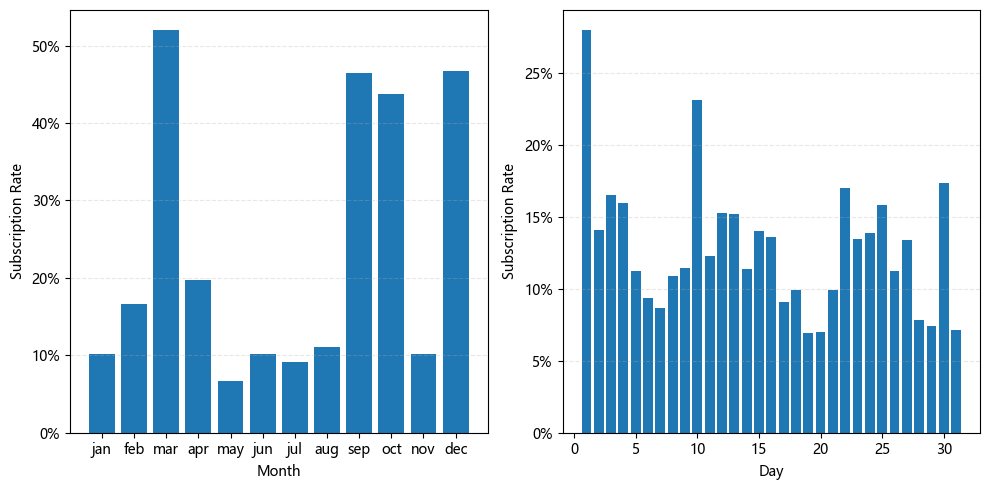

In [18]:
# 上一次联系月份与日期和订阅率
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

# 1. 上一次联系月份与订阅率
month_rate = df_3.groupby('month')['subscribed'].mean().reindex(['jan', 'feb', 'mar', 'apr', 'may', 'jun', 'jul', 'aug', 'sep', 'oct', 'nov', 'dec'])
axes[0].bar(month_rate.index, month_rate.values)
axes[0].set_xlabel('Month')
axes[0].set_ylabel('Subscription Rate')

# 2. 上一次联系日期与订阅率
date_rate = df_3.groupby('day')['subscribed'].mean()
axes[1].bar(date_rate.index, date_rate.values)
axes[1].set_xlabel('Day')
axes[1].set_ylabel('Subscription Rate')

for ax in axes:
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.0%}'))
    ax.grid(axis='y', linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

可以看到，月份和不同日期的订阅率有一定差异，但无明显规律，后续考虑进行独热编码

# 3. 总结

1. 对 balance、campaign、previous 尝试对数变换。对于余额，由于存在负数，使用保留正负号的对数变换
2. 对于pdays，区分客户以前是否被联系过，以及联系过的客户距离上次联系有多少天。
3. 对于年龄可以考虑分箱
4. 其他正常进行独热编码或者二分类